In [ ]:
import os
import zipfile
import shutil
import random
import torch
import torchvision.transforms as transforms
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader, random_split
from PIL import Image
from tqdm import tqdm

# ======================
# STEP 1: UNZIP DATASET
# ======================
zip_path = "/content/Extracted.zip"
extract_path = "/content/OASIS00"

if os.path.exists(extract_path):
    shutil.rmtree(extract_path)

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("✅ Dataset extracted.")

✅ Dataset extracted.


In [ ]:
# ================================
# STEP 2: RESIZE IMAGES TO 224x224
# ================================
target_size = (224, 224)
classes = ["MildDemented", "ModerateDemented", "NonDemented", "VeryMildDemented"]

for cls in classes:
    class_dir = os.path.join(extract_path, cls)
    if not os.path.exists(class_dir):
        print(f"⚠️ Warning: Class directory not found: {class_dir}")
        continue

    print(f"\n📁 Resizing images in class: {cls}")
    for filename in tqdm(os.listdir(class_dir), desc=f"Resizing {cls}"):
        file_path = os.path.join(class_dir, filename)
        try:
            with Image.open(file_path) as img:
                img = img.convert("RGB")
                img_resized = img.resize(target_size)
                img_resized.save(file_path)
        except Exception as e:
            print(f"❌ Error resizing {filename}: {e}")

print("\n🎉 All images resized to 224x224 successfully!")


📁 Resizing images in class: MildDemented


Resizing MildDemented: 100%|██████████| 160/160 [00:00<00:00, 178.43it/s]



📁 Resizing images in class: ModerateDemented


Resizing ModerateDemented: 100%|██████████| 80/80 [00:00<00:00, 186.59it/s]



📁 Resizing images in class: NonDemented


Resizing NonDemented: 100%|██████████| 1060/1060 [00:05<00:00, 180.93it/s]



📁 Resizing images in class: VeryMildDemented


Resizing VeryMildDemented: 100%|██████████| 420/420 [00:02<00:00, 182.63it/s]


🎉 All images resized to 224x224 successfully!


In [ ]:
# ================================
# STEP 3: Train-Validation-Test Split
# ================================
# Evaluation transform
transform_eval = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor(),
    transforms.Normalize([0.5], [0.5])
])

# Load dataset with eval transform first
full_dataset = ImageFolder(root=extract_path, transform=transform_eval)
class_names = full_dataset.classes
print("Classes:", class_names)

# Split sizes
dataset_size = len(full_dataset)
train_size = int(0.6 * dataset_size)
val_size = int(0.2 * dataset_size)
test_size = dataset_size - train_size - val_size

train_dataset, val_dataset, test_dataset = random_split(
    full_dataset, [train_size, val_size, test_size], generator=torch.Generator().manual_seed(42)
)

Classes: ['MildDemented', 'ModerateDemented', 'NonDemented', 'VeryMildDemented']


In [ ]:
# ================================
# STEP 4: Training Augmentation (only for training set)
# ================================
augment_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(20),
    transforms.ColorJitter(0.2, 0.2, 0.2),
    transforms.Resize((256, 256))
])

def augment_train_dataset(train_dataset, target_count_per_class=2000):
    dataset = train_dataset.dataset
    indices = train_dataset.indices

    # Group training indices by class
    class_to_indices = {i: [] for i in range(len(dataset.classes))}
    for idx in indices:
        label = dataset.imgs[idx][1]
        class_to_indices[label].append(idx)

    for cls_idx, idx_list in class_to_indices.items():
        existing_count = len(idx_list)
        needed = target_count_per_class - existing_count
        if needed <= 0:
            continue

        for i in range(needed):
            img_idx = random.choice(idx_list)
            img_path, label = dataset.imgs[img_idx]
            image = Image.open(img_path).convert("RGB")
            augmented = augment_transform(image)
            # Save augmented image with unique name
            base_dir = os.path.dirname(img_path)
            augmented.save(os.path.join(base_dir, f"aug_{i}_{os.path.basename(img_path)}"))

# Apply augmentation only on training set
augment_train_dataset(train_dataset, target_count_per_class=2000)

In [ ]:
# ================================
# STEP 5: Define final transforms
# ================================
transform_train = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize([0.5], [0.5])
])

# Assign transforms
train_dataset.dataset.transform = transform_train  # only training
val_dataset.dataset.transform = transform_eval     # validation
test_dataset.dataset.transform = transform_eval    # test

# ================================
# STEP 6: DataLoaders
# ================================
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

print("✅ Split done. Training augmentation applied only to training set.")

✅ Split done. Training augmentation applied only to training set.


In [ ]:
# ===============================
# STEP 5 (UPDATED): Fine-tune ConvNeXt
# ===============================
from torchvision import models
import torch.nn as nn
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load pretrained ConvNeXt-Small
model = models.convnext_small(pretrained=True)

# ✅ UNFREEZE last few layers for fine-tuning (instead of freezing all)
for name, param in model.features.named_parameters():
    if "8" in name or "9" in name:  # Fine-tune final blocks
        param.requires_grad = True
    else:
        param.requires_grad = False

# ✅ Modify classification head for 4 classes
num_features = model.classifier[2].in_features
model.classifier[2] = nn.Linear(num_features, len(class_names))  # class_names = 4-class list
model = model.to(device)

print("✅ Model loaded, classification head modified, and selected layers unfrozen for fine-tuning.")

/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ConvNeXt_Small_Weights.IMAGENET1K_V1`. You can also use `weights=ConvNeXt_Small_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/convnext_small-0c510722.pth" to /root/.cache/torch/hub/checkpoints/convnext_small-0c510722.pth


100%|██████████| 192M/192M [00:01<00:00, 177MB/s]


✅ Model loaded, classification head modified, and selected layers unfrozen for fine-tuning.


In [ ]:
# ========================
# STEP 6: Train the Model
# ========================
import torch
import torch.nn as nn
import torch.optim as optim
import torch.optim.lr_scheduler as lr_scheduler
from tqdm import tqdm

# ✅ Loss Function (You can use weighted loss if class imbalance is present)
criterion = nn.CrossEntropyLoss()

# ✅ Optimizer: AdamW with a low learning rate
optimizer = optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=0.0001
)

# Learning Rate Scheduler: ReduceLROnPlateau
scheduler = lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode='max',       # monitoring validation accuracy
    factor=0.5,       # reduce LR by half on plateau
    patience=2        # wait 2 epochs with no improvement
    # verbose=True    # comment/remove if PyTorch version <1.11
)

print("✅ Loss function, AdamW optimizer, and LR scheduler are set.")

num_epochs = 20

# ✅ Lists for tracking metrics
train_losses, val_losses, train_accs, val_accs = [], [], [], []

for epoch in range(num_epochs):
    # Training Phase
    model.train()
    train_loss = 0.0
    correct_train = 0
    total_train = 0

    for images, labels in tqdm(train_loader, desc=f"Epoch {epoch+1}/{num_epochs} - Training"):
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        train_loss += loss.item()
        _, predicted = torch.max(outputs.data, 1)
        total_train += labels.size(0)
        correct_train += (predicted == labels).sum().item()

    avg_train_loss = train_loss / len(train_loader)
    train_accuracy = correct_train / total_train

    # Validation Phase
    model.eval()
    val_loss = 0.0
    correct_val = 0
    total_val = 0

    with torch.no_grad():
        for images, labels in tqdm(val_loader, desc=f"Epoch {epoch+1}/{num_epochs} - Validation"):
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            val_loss += loss.item()

            _, predicted = torch.max(outputs.data, 1)
            total_val += labels.size(0)
            correct_val += (predicted == labels).sum().item()

    avg_val_loss = val_loss / len(val_loader)
    val_accuracy = correct_val / total_val

    # ✅ Save metrics for plotting
    train_losses.append(avg_train_loss)
    val_losses.append(avg_val_loss)
    train_accs.append(train_accuracy)
    val_accs.append(val_accuracy)

    # ✅ Step the scheduler with validation accuracy
    scheduler.step(val_accuracy)

    print(f"📅 Epoch {epoch+1}/{num_epochs} — "
          f"Train Loss: {avg_train_loss:.4f}, Train Acc: {train_accuracy:.4f} — "
          f"Val Loss: {avg_val_loss:.4f}, Val Acc: {val_accuracy:.4f}")

✅ Loss function, AdamW optimizer, and LR scheduler are set.


Epoch 1/20 - Validation: 100%|██████████| 11/11 [00:06<00:00,  1.62it/s]


📅 Epoch 1/20 — Train Loss: 1.0519, Train Acc: 0.5891 — Val Loss: 0.9112, Val Acc: 0.6337


Epoch 2/20 - Validation: 100%|██████████| 11/11 [00:04<00:00,  2.55it/s]


📅 Epoch 2/20 — Train Loss: 0.8819, Train Acc: 0.6279 — Val Loss: 0.8011, Val Acc: 0.6250


Epoch 3/20 - Validation: 100%|██████████| 11/11 [00:04<00:00,  2.47it/s]


... (31 outputs left out)

Epoch 19/20 - Validation: 100%|██████████| 11/11 [00:04<00:00,  2.46it/s]


📅 Epoch 19/20 — Train Loss: 0.0400, Train Acc: 0.9922 — Val Loss: 0.0178, Val Acc: 0.9971


Epoch 20/20 - Validation: 100%|██████████| 11/11 [00:04<00:00,  2.45it/s]

📅 Epoch 20/20 — Train Loss: 0.0501, Train Acc: 0.9874 — Val Loss: 0.0207, Val Acc: 0.9971


In [ ]:
from sklearn.metrics import (
    classification_report, confusion_matrix, accuracy_score,
    precision_score, recall_score, f1_score, balanced_accuracy_score
)
import numpy as np
import pandas as pd
from sklearn.utils import resample

# ==========================
# STEP 7: Evaluate on OASIS Test Set
# ==========================
model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, preds = torch.max(outputs, 1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# Convert to numpy arrays
y_true = np.array(all_labels)
y_pred = np.array(all_preds)

# Class names
class_names = full_dataset.classes

# --------------------------
# Basic Metrics
# --------------------------
print("📊 Classification Report:\n")
print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

cm = confusion_matrix(y_true, y_pred)
print("\n🧮 Confusion Matrix:")
print(cm)

accuracy = accuracy_score(y_true, y_pred)
bal_acc = balanced_accuracy_score(y_true, y_pred)

print(f"\n✅ Accuracy: {accuracy:.4f}")
print(f"⚖️ Balanced Accuracy: {bal_acc:.4f}")

# Per-class metrics
precision = precision_score(y_true, y_pred, average=None)
recall = recall_score(y_true, y_pred, average=None)
f1 = f1_score(y_true, y_pred, average=None)

# --------------------------
# Specificity & Misclassification Rate
# --------------------------
specificity = []
misclassification_rate = []
N = cm.sum()

for i in range(len(class_names)):
    TP = cm[i, i]
    FN = cm[i, :].sum() - TP
    FP = cm[:, i].sum() - TP
    TN = N - (TP + FN + FP)

    spec = TN / (TN + FP) if (TN + FP) > 0 else 0
    miss_rate = (FP + FN) / N

    specificity.append(spec)
    misclassification_rate.append(miss_rate)

df = pd.DataFrame({
    'Class': class_names,
    'Precision': precision,
    'Recall': recall,
    'F1-Score': f1,
    'Specificity': specificity,
    'Misclassification Rate': misclassification_rate
})

print("\n📋 Detailed Metrics per Class:")
print(df.round(4))

# =====================================================
# ✅ COMMENT 2: BOOTSTRAP CONFIDENCE INTERVALS
# =====================================================

def bootstrap_ci(y_true, y_pred, metric_func, n_bootstrap=1000, alpha=0.05):
    scores = []

    for _ in range(n_bootstrap):
        idx = resample(np.arange(len(y_true)), replace=True, n_samples=len(y_true))
        score = metric_func(y_true[idx], y_pred[idx])
        scores.append(score)

    lower = np.percentile(scores, 100 * alpha / 2)
    upper = np.percentile(scores, 100 * (1 - alpha / 2))
    return np.mean(scores), lower, upper

# ---- Overall accuracy CI ----
mean_acc, acc_low, acc_high = bootstrap_ci(
    y_true, y_pred, accuracy_score, n_bootstrap=1000
)

print("\n📈 BOOTSTRAP CONFIDENCE INTERVALS (95%)")
print(f"Accuracy: {mean_acc:.4f}  [ {acc_low:.4f} , {acc_high:.4f} ]")

# ---- Per-class Recall & F1 CI ----
print("\nPer-class 95% Confidence Intervals:")

ci_table = []

for i, cname in enumerate(class_names):

    # recall CI
    mean_rec, rec_low, rec_high = bootstrap_ci(
        y_true, y_pred,
        lambda yt, yp: recall_score(yt, yp, average=None)[i],
        n_bootstrap=500
    )

    # f1 CI
    mean_f1, f1_low, f1_high = bootstrap_ci(
        y_true, y_pred,
        lambda yt, yp: f1_score(yt, yp, average=None)[i],
        n_bootstrap=500
    )

    print(f"\n🔹 {cname}")
    print(f"Recall: {mean_rec:.4f}  [ {rec_low:.4f} , {rec_high:.4f} ]")
    print(f"F1:     {mean_f1:.4f}  [ {f1_low:.4f} , {f1_high:.4f} ]")

    ci_table.append({
        "Class": cname,
        "Recall_mean": mean_rec,
        "Recall_low": rec_low,
        "Recall_high": rec_high,
        "F1_mean": mean_f1,
        "F1_low": f1_low,
        "F1_high": f1_high
    })

ci_df = pd.DataFrame(ci_table)
print("\n📋 CI Summary Table:")
print(ci_df.round(4))

📊 Classification Report:

                  precision    recall  f1-score   support

    MildDemented     1.0000    0.9730    0.9863        37
ModerateDemented     1.0000    1.0000    1.0000        12
     NonDemented     0.9950    1.0000    0.9975       201
VeryMildDemented     1.0000    1.0000    1.0000        94

        accuracy                         0.9971       344
       macro avg     0.9988    0.9932    0.9960       344
    weighted avg     0.9971    0.9971    0.9971       344


🧮 Confusion Matrix:
[[ 36   0   1   0]
 [  0  12   0   0]
 [  0   0 201   0]
 [  0   0   0  94]]

✅ Accuracy: 0.9971
⚖️ Balanced Accuracy: 0.9932

📋 Detailed Metrics per Class:
              Class  Precision  Recall  F1-Score  Specificity  \
0      MildDemented      1.000   0.973    0.9863        1.000   
1  ModerateDemented      1.000   1.000    1.0000        1.000   
2       NonDemented      0.995   1.000    0.9975        0.993   
3  VeryMildDemented      1.000   1.000    1.0000        1.000   

   

In [ ]:
import torch
import numpy as np
import cv2
from tqdm import tqdm

# ==========================
# Grad-CAM FUNCTION
# ==========================
def generate_gradcam(model, image, target_class):
    model.eval()

    gradients = []
    activations = []

    def backward_hook(module, grad_in, grad_out):
        gradients.append(grad_out[0])

    def forward_hook(module, inp, out):
        activations.append(out)

    # Last conv layer (ConvNeXt)
    target_layer = model.features[-1]

    handle_f = target_layer.register_forward_hook(forward_hook)
    handle_b = target_layer.register_backward_hook(backward_hook)

    output = model(image)
    loss = output[0, target_class]
    model.zero_grad()
    loss.backward()

    grads = gradients[0]
    acts = activations[0]

    weights = torch.mean(grads, dim=(2, 3), keepdim=True)
    cam = torch.sum(weights * acts, dim=1).squeeze()

    cam = torch.relu(cam)
    cam = cam.detach().cpu().numpy()

    cam = cv2.resize(cam, (256, 256))
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

    handle_f.remove()
    handle_b.remove()

    return cam


# ==========================
# Dice & IoU FUNCTIONS
# ==========================
def dice_score(pred, gt):
    intersection = np.sum(pred * gt)
    return (2. * intersection) / (np.sum(pred) + np.sum(gt) + 1e-8)

def iou_score(pred, gt):
    intersection = np.sum(pred * gt)
    union = np.sum(pred) + np.sum(gt) - intersection
    return intersection / (union + 1e-8)


# ==========================
# ROI OVERLAP EVALUATION
# ==========================
model.eval()

dice_scores = []
iou_scores = []

for images, labels in tqdm(test_loader, desc="ROI Evaluation"):
    images = images.to(device)
    labels = labels.to(device)

    outputs = model(images)
    _, preds = torch.max(outputs, 1)

    for i in range(images.size(0)):
        img = images[i].unsqueeze(0)
        pred_class = preds[i].item()

        # Grad-CAM
        cam = generate_gradcam(model, img, pred_class)

        # --------------------------
        # Predicted ROI mask
        # --------------------------
        cam_thresh = (cam > 0.2).astype(np.uint8)

        # --------------------------
        # Ground truth (pseudo brain mask)
        # --------------------------
        img_np = images[i].cpu().numpy()[0]  # grayscale

        # Normalize
        img_np = (img_np - img_np.min()) / (img_np.max() - img_np.min() + 1e-8)

        # Threshold to get brain region
        brain_mask = (img_np > 0.1).astype(np.uint8)

        # --------------------------
        # Compute metrics
        # --------------------------
        dice = dice_score(cam_thresh, brain_mask)
        iou = iou_score(cam_thresh, brain_mask)

        dice_scores.append(dice)
        iou_scores.append(iou)

# ==========================
# FINAL RESULTS
# ==========================
print("\n📊 ROI OVERLAP RESULTS:")
print(f"Mean Dice Score: {np.mean(dice_scores):.4f}")
print(f"Mean IoU Score:  {np.mean(iou_scores):.4f}")

ROI Evaluation:   0%|          | 0/11 [00:00<?, ?it/s]/usr/local/lib/python3.12/dist-packages/torch/nn/modules/module.py:1867: FutureWarning: Using a non-full backward hook when the forward contains multiple autograd Nodes is deprecated and will be removed in future versions. This hook will be missing some grad_input. Please use register_full_backward_hook to get the documented behavior.
  self._maybe_warn_non_full_backward_hook(args, result, grad_fn)
ROI Evaluation: 100%|██████████| 11/11 [00:19<00:00,  1.74s/it]


📊 ROI OVERLAP RESULTS:
Mean Dice Score: 0.6462
Mean IoU Score:  0.4851


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
import numpy as np
import pandas as pd

# STEP 7: Evaluate the Model
# ==========================
model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# Convert to NumPy arrays
y_true = np.array(all_labels)
y_pred = np.array(all_preds)

# Class names
class_names = full_dataset.classes

# 📊 Classification Report
print("📊 Classification Report:\n")
print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

# ✅ Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
print("\n🧮 Confusion Matrix:")
print(cm)

# ✅ Accuracy
accuracy = accuracy_score(y_true, y_pred)
print(f"\n✅ Accuracy: {accuracy:.4f}")

# ✅ Class-wise metrics
precision = precision_score(y_true, y_pred, average=None)
recall = recall_score(y_true, y_pred, average=None)
f1 = f1_score(y_true, y_pred, average=None)

# ✅ Specificity and Misclassification Rate
specificity = []
misclassification_rate = []
num_classes = len(class_names)

for i in range(num_classes):
    TP = cm[i, i]
    FN = cm[i, :].sum() - TP
    FP = cm[:, i].sum() - TP
    TN = cm.sum() - (TP + FN + FP)

    spec = TN / (TN + FP) if (TN + FP) > 0 else 0
    miss_rate = (FP + FN) / cm.sum()

    specificity.append(spec)
    misclassification_rate.append(miss_rate)

# ✅ Summarize Metrics in Table
df = pd.DataFrame({
    'Class': class_names,
    'Precision': precision,
    'Recall': recall,
    'F1-Score': f1,
    'Specificity': specificity,
    'Misclassification Rate': misclassification_rate
})

print("\n📋 Detailed Metrics per Class:")
print(df.round(4))

# Optional: Save report to CSV
# df.to_csv("classification_metrics.csv", index=False)

📊 Classification Report:

                  precision    recall  f1-score   support

    MildDemented     1.0000    0.9730    0.9863        37
ModerateDemented     1.0000    1.0000    1.0000        12
     NonDemented     0.9950    1.0000    0.9975       201
VeryMildDemented     1.0000    1.0000    1.0000        94

        accuracy                         0.9971       344
       macro avg     0.9988    0.9932    0.9960       344
    weighted avg     0.9971    0.9971    0.9971       344


🧮 Confusion Matrix:
[[ 36   0   1   0]
 [  0  12   0   0]
 [  0   0 201   0]
 [  0   0   0  94]]

✅ Accuracy: 0.9971

📋 Detailed Metrics per Class:
              Class  Precision  Recall  F1-Score  Specificity  \
0      MildDemented      1.000   0.973    0.9863        1.000   
1  ModerateDemented      1.000   1.000    1.0000        1.000   
2       NonDemented      0.995   1.000    0.9975        0.993   
3  VeryMildDemented      1.000   1.000    1.0000        1.000   

   Misclassification Rate  
0   

Added noise to prediction scores. Shape: (344, 4)
🧪 Simulated Noisy AUC for class MildDemented: 0.9695
🧪 Simulated Noisy AUC for class ModerateDemented: 0.9880
🧪 Simulated Noisy AUC for class NonDemented: 0.9758
🧪 Simulated Noisy AUC for class VeryMildDemented: 0.9929


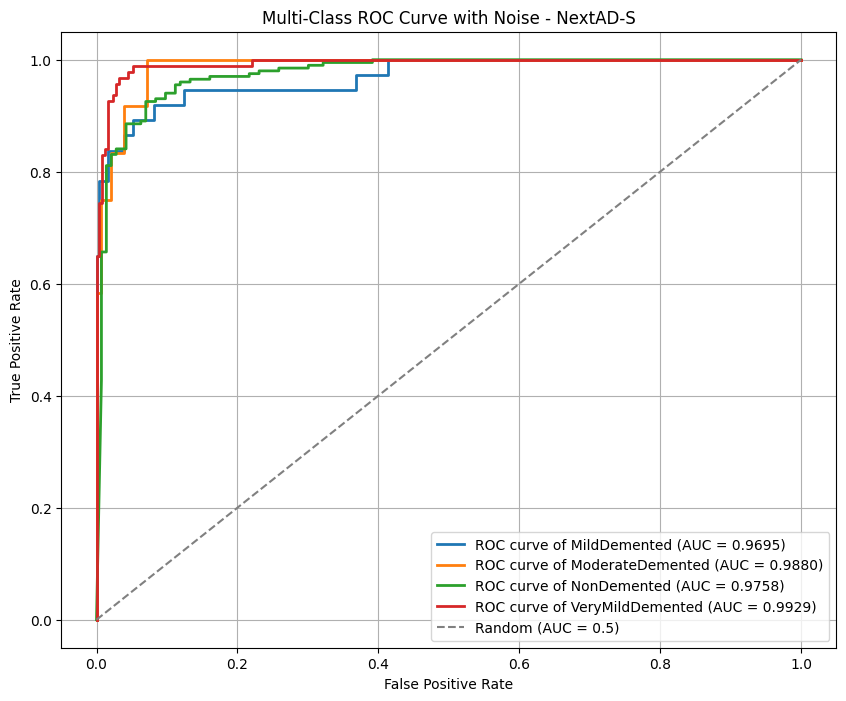

In [ ]:
from sklearn.metrics import roc_curve, auc, classification_report
from sklearn.preprocessing import label_binarize
import matplotlib.pyplot as plt
import numpy as np

# ✅ Step 1: Get prediction probabilities
model.eval()
all_probs = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        probs = torch.softmax(outputs, dim=1)  # probabilities
        all_probs.extend(probs.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

Y_Score = np.array(all_probs)   # shape: (num_samples, num_classes)
y_true = np.array(all_labels)

# ✅ Step 2: Add Gaussian noise to prediction probabilities
noise_level = 0.3   # adjust this to control noise intensity
Y_Score_noisy = Y_Score + np.random.normal(0, noise_level, Y_Score.shape)

# Clip to valid probability range [0, 1]
Y_Score_noisy = np.clip(Y_Score_noisy, 0, 1)

print("Added noise to prediction scores. Shape:", Y_Score_noisy.shape)

# ✅ Step 3: One-vs-Rest binarization for ROC
y_test_bin = label_binarize(y_true, classes=np.arange(len(class_names)))

# ✅ Step 4: Compute ROC & AUC for each class (with noisy probs)
fpr, tpr, roc_auc = {}, {}, {}
for i, class_name in enumerate(class_names):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], Y_Score_noisy[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])
    print(f"🧪 Simulated Noisy AUC for class {class_name}: {roc_auc[i]:.4f}")

# ✅ Step 5: Plot ROC curves
plt.figure(figsize=(10, 8))
for i, class_name in enumerate(class_names):
    plt.plot(fpr[i], tpr[i], lw=2,
             label=f"ROC curve of {class_name} (AUC = {roc_auc[i]:.4f})")

# Random baseline
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label="Random (AUC = 0.5)")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Multi-Class ROC Curve with Noise - NextAD-S")
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

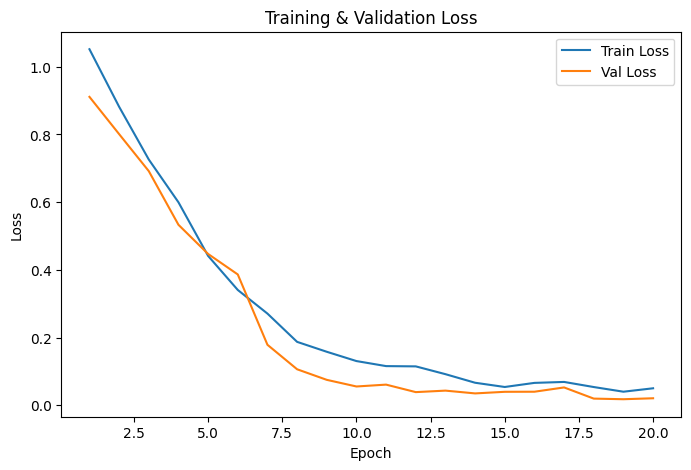

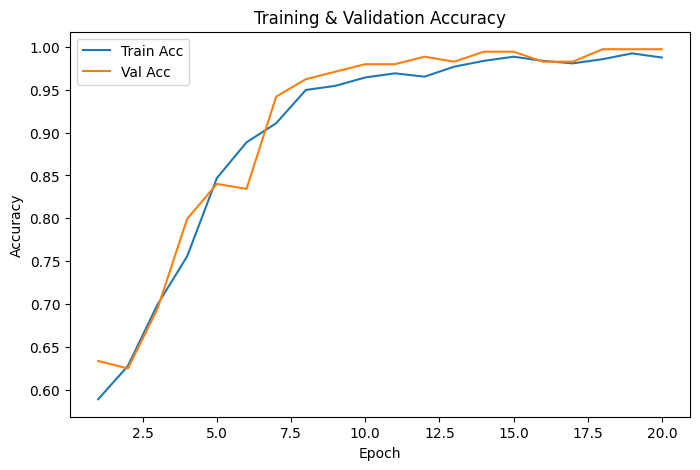

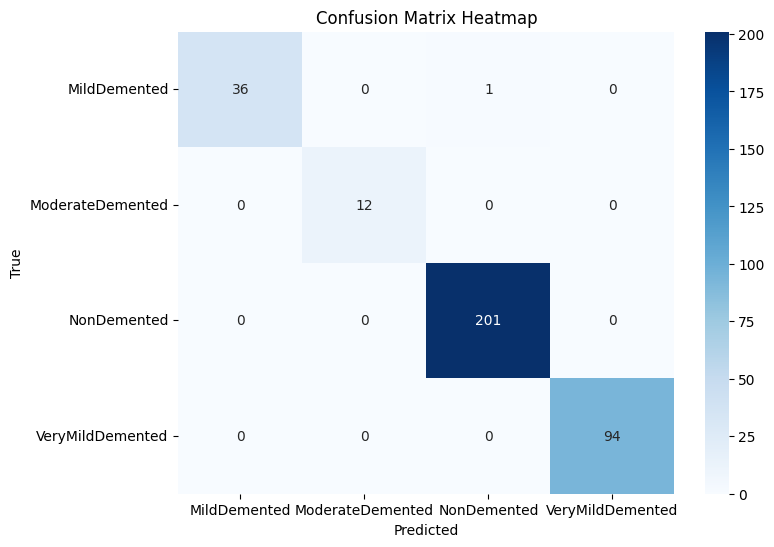

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# ===============================
# STEP 8: Plot Accuracy & Loss Graphs
# ===============================

# Plot Loss
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(train_losses)+1), train_losses, label="Train Loss")
plt.plot(range(1, len(val_losses)+1), val_losses, label="Val Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training & Validation Loss")
plt.legend()
plt.show()

# Plot Accuracy
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(train_accs)+1), train_accs, label="Train Acc")
plt.plot(range(1, len(val_accs)+1), val_accs, label="Val Acc")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training & Validation Accuracy")
plt.legend()
plt.show()

# ===============================
# STEP 9: Confusion Matrix Heatmap
# ===============================
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix Heatmap")
plt.show()

/usr/local/lib/python3.12/dist-packages/torch/nn/modules/module.py:1867: FutureWarning: Using a non-full backward hook when the forward contains multiple autograd Nodes is deprecated and will be removed in future versions. This hook will be missing some grad_input. Please use register_full_backward_hook to get the documented behavior.
  self._maybe_warn_non_full_backward_hook(args, result, grad_fn)


✅ Correct Prediction at index 0


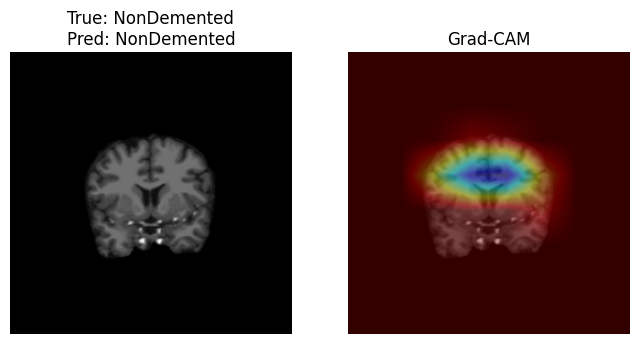

✅ Correct Prediction at index 1


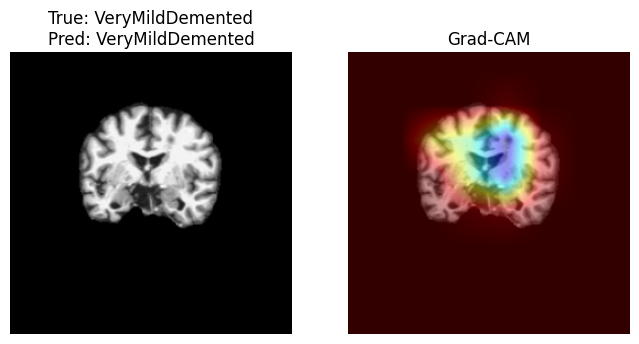

✅ Correct Prediction at index 2


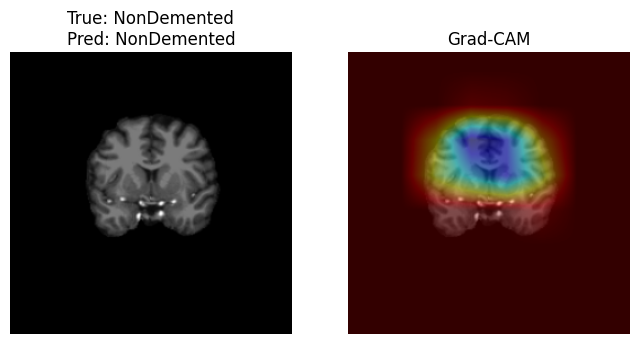

✅ Correct Prediction at index 3


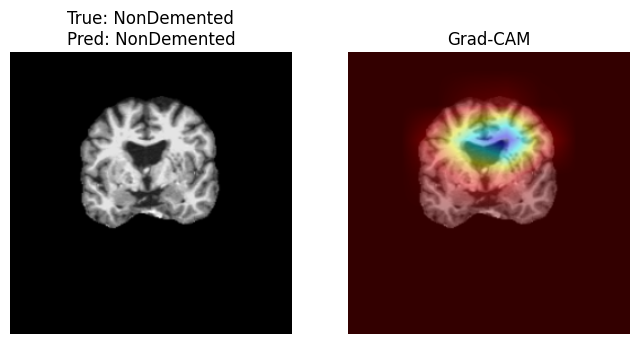

✅ Correct Prediction at index 4


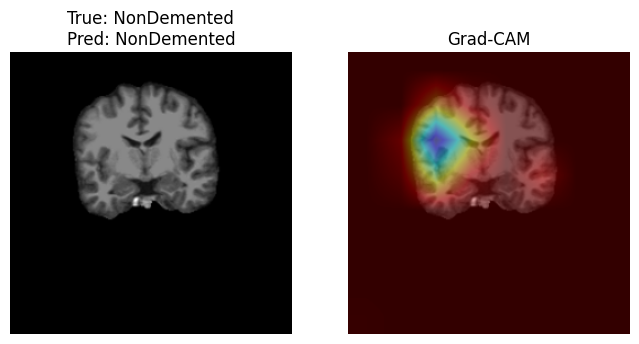

✅ Correct Prediction at index 5


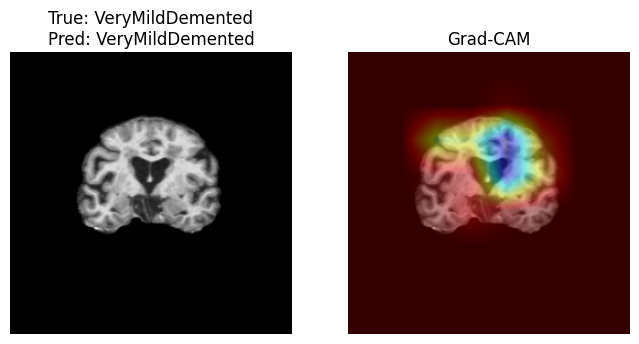

✅ Correct Prediction at index 6


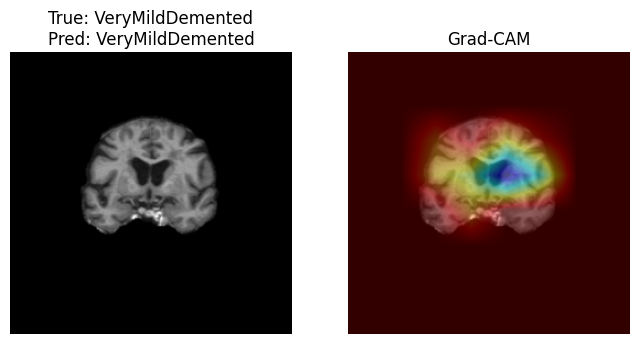

✅ Correct Prediction at index 7


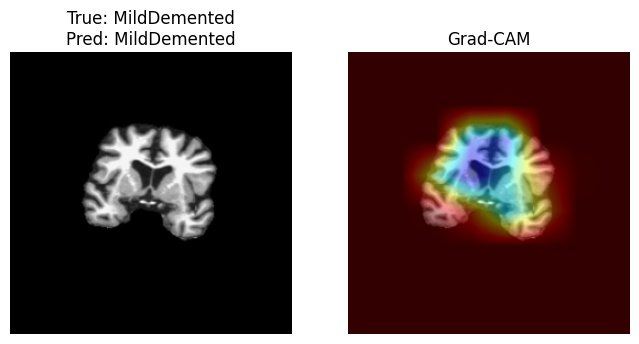

✅ Correct Prediction at index 8


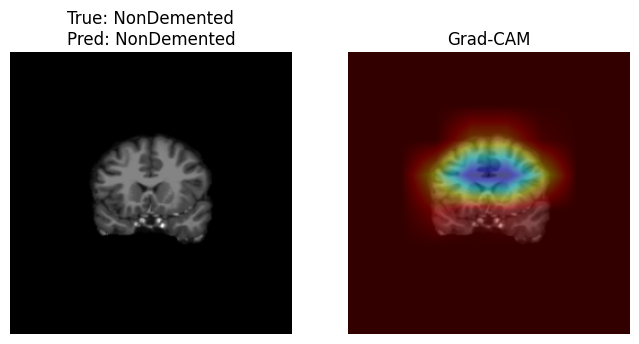

✅ Correct Prediction at index 9


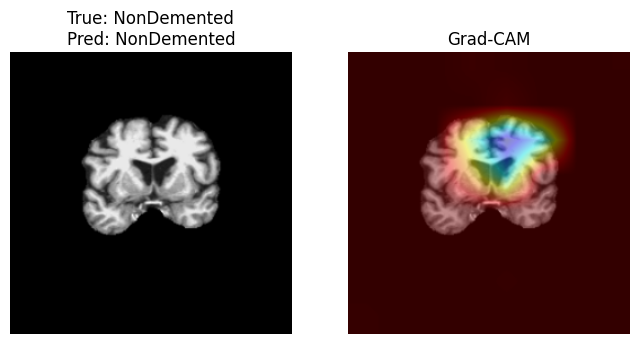

In [ ]:
# ==============================
# STEP 8: Grad-CAM Visualization
# ==============================
import torch
import numpy as np
import matplotlib.pyplot as plt
import cv2

# ✅ Grad-CAM function
def generate_gradcam(model, image_tensor, target_class, last_conv_layer="features.7"):
    model.eval()
    conv_output = None
    gradients = None

    def forward_hook(module, inp, out):
        nonlocal conv_output
        conv_output = out

    def backward_hook(module, grad_in, grad_out):
        nonlocal gradients
        gradients = grad_out[0]

    # Register hooks
    layer = dict([*model.named_modules()])[last_conv_layer]
    fh = layer.register_forward_hook(forward_hook)
    bh = layer.register_backward_hook(backward_hook)

    # Forward pass
    image_tensor = image_tensor.unsqueeze(0).to(device)
    output = model(image_tensor)
    pred_class = output.argmax(dim=1).item()

    # Backward pass
    model.zero_grad()
    class_loss = output[0, target_class]
    class_loss.backward()

    # Remove hooks
    fh.remove()
    bh.remove()

    # Compute Grad-CAM
    pooled_gradients = torch.mean(gradients, dim=[0, 2, 3])
    conv_output = conv_output[0]

    for i in range(conv_output.shape[0]):
        conv_output[i, ...] *= pooled_gradients[i]

    heatmap = torch.mean(conv_output, dim=0).cpu().detach().numpy()
    heatmap = np.maximum(heatmap, 0)
    heatmap = heatmap / (heatmap.max() + 1e-8)

    return heatmap, pred_class

# ✅ Function to display Grad-CAM
def show_gradcam(image, heatmap, true_label, pred_label):
    image = image.permute(1, 2, 0).cpu().numpy()
    image = (image - image.min()) / (image.max() - image.min())  # normalize 0-1
    image = np.uint8(255 * image)

    heatmap_resized = cv2.resize(heatmap, (image.shape[1], image.shape[0]))
    heatmap_colored = cv2.applyColorMap(np.uint8(255 * heatmap_resized), cv2.COLORMAP_JET)
    superimposed = cv2.addWeighted(image, 0.6, heatmap_colored, 0.4, 0)

    plt.figure(figsize=(8,4))
    plt.subplot(1,2,1)
    plt.imshow(image)
    plt.title(f"True: {class_names[true_label]}\nPred: {class_names[pred_label]}")
    plt.axis("off")

    plt.subplot(1,2,2)
    plt.imshow(superimposed)
    plt.title("Grad-CAM")
    plt.axis("off")
    plt.show()

# ==============================
# STEP 9: Visualize correct & wrong predictions
# ==============================
# Convert test_dataset into list for indexing
test_samples = list(test_dataset)

# Pick a few samples (correct & wrong)
for idx in range(10):  # check first 10
    image, true_label = test_samples[idx]
    heatmap, pred_label = generate_gradcam(model, image, target_class=true_label, last_conv_layer="features.7")

    # Show only correct and wrong separately
    if pred_label == true_label:
        print(f"✅ Correct Prediction at index {idx}")
    else:
        print(f"❌ Wrong Prediction at index {idx}")

    show_gradcam(image, heatmap, true_label, pred_label)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os

save_dir = "/content/drive/MyDrive/alzheimer_maxvit_model"
os.makedirs(save_dir, exist_ok=True)

model_path = os.path.join(save_dir, "maxvit_best_model.pth")

In [ ]:
import torch

# Save only best trained weights (recommended)
torch.save(model.state_dict(), model_path)

print(f"✅ Model saved successfully at: {model_path}")

✅ Model saved successfully at: /content/drive/MyDrive/alzheimer_maxvit_model/maxvit_best_model.pth
